# Interpretability 3: KAN Compiler

We have shown in many examples how to extract symbolic formulas from KANs. Now we want to consider the reverse task: compiling a symbolic formula into KANs. This might be needed for many reasons. One use case is that we have prior knowledge which is the approximate ground truth (empirical/constitutive laws etc.) and we want to build this knowledge into neural networks and only fine tune the network to real data.

cuda


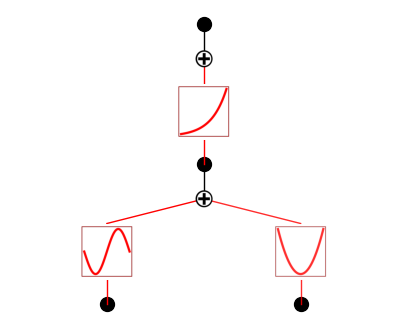

In [1]:
from sympy import *
import torch
from xkan.interp import expand_depth, expand_width, perturb
from xkan.symbolic import compile_formula
from xkan.utils import create_dataset
from xkan.viz import plot

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

input_variables = x,y = symbols('x y')
expr = exp(sin(pi*x)+y**2)

model = compile_formula(input_variables, expr).to(device)

f = lambda x: torch.exp(torch.sin(torch.pi*x[:,0]) + x[:,1]**2)
train, test = create_dataset(f, n_var=2, device=device)

plot(model, train['x']);

if you want more complicated formulas, you can load in an equation in the Feynman dataset.

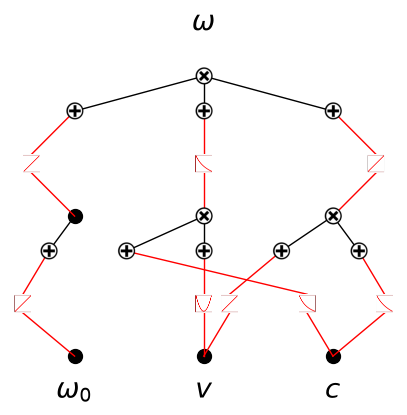

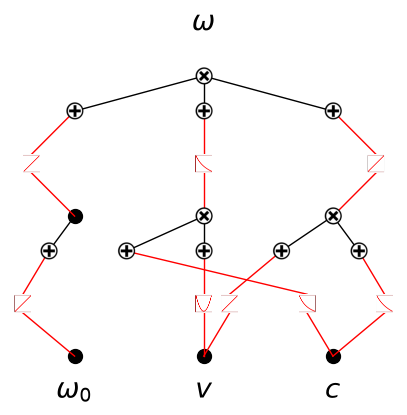

In [2]:
from xkan.contrib.feynman import get_feynman_dataset
import matplotlib.pyplot as plt

problem_id = 36 # problem_id in 1-120
input_variables, expr, f, ranges = get_feynman_dataset(problem_id)
n_var = len(input_variables)
model = compile_formula(input_variables, expr)

train, test = create_dataset(f, n_var=n_var, ranges=ranges)
#plot(model, train['x'], in_vars=input_variables, out_vars=[expr], beta=10000, title='P{}'.format(problem_id))
plot(model, train['x'], in_vars=input_variables, out_vars=[symbols('omega')], beta=10000)
#plt.savefig('./fig1.pdf', bbox_inches='tight', dpi=200)

We can check that the model indeed achieves zero loss (near machine precision) on the data

In [3]:
torch.mean((model(train['x'])-train['y'])**2)

tensor(1.5383e-15, grad_fn=<MeanBackward0>)

Suppose the symbolic formula approximates the ground truth and you want to fine-tune the model on real data. The model has the symbolic front on and the spline front off, so the affine parameters of the symbolic equations are the only trainable ones. Pick the expressive power you need:

* To keep the symbolic functions and train their affine parameters, change nothing.
* To make the functions trainable, call `perturb(model)`. `mode='minimal'` makes the active functions trainable and keeps the dead ones dead; `mode='all'` (the default) lets dead functions come back.
* If the ground truth needs a larger network, expand it with `expand_width` or `expand_depth` (each returns the expanded network), then call `perturb(model)`.

The rest of this notebook takes the last route and expands the network first.

step 1: expand depth, add an extra linear function in the end

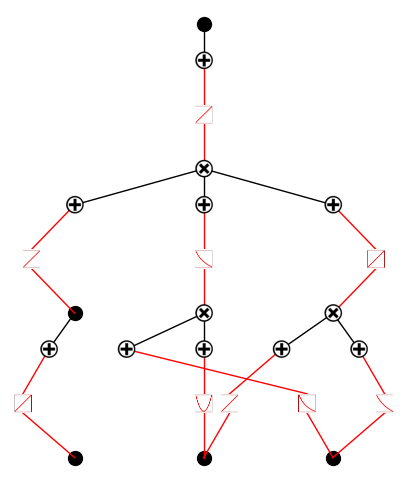

In [4]:
model = expand_depth(model)
plot(model, train['x']);

step 2: add two addition nodes in layer 1.

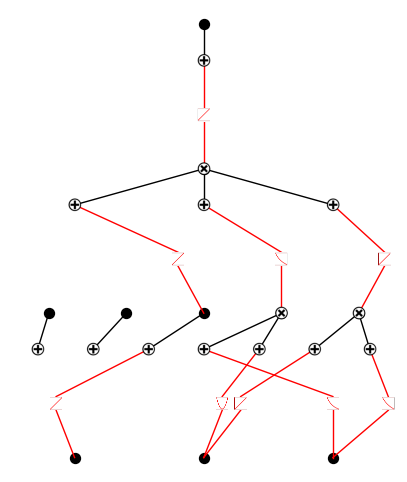

In [5]:
model = expand_width(model, 1, 2)
plot(model, train['x']);

step 3: add two multiplication nodes in layer 2, with arity 2 and 3.

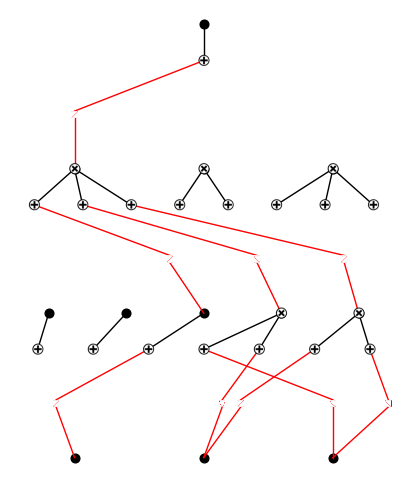

In [6]:
model = expand_width(model, 2, 2, sum_bool=False, mult_arity=[2,3])
plot(model, train['x']);

step 4: now we perturb all edges (mode='minimal' only perturb the currently active edges, mode='all' perturbs all neurons).

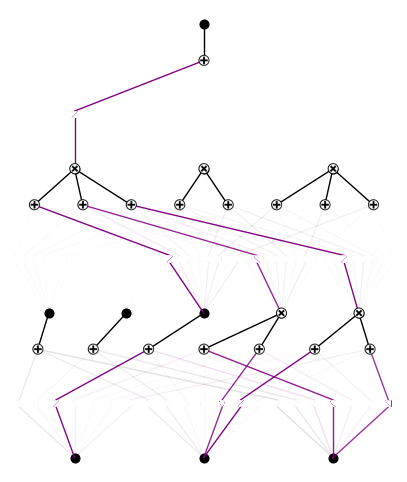

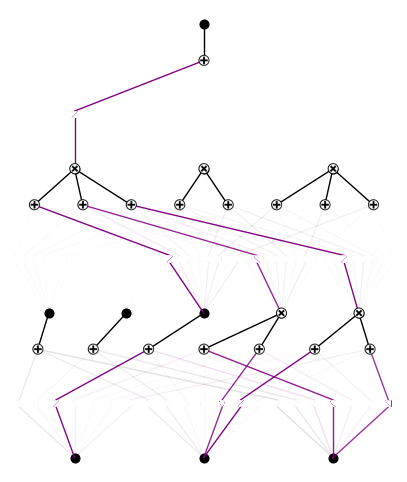

In [7]:
perturb(model, mag=0.1, mode='all')
plot(model, train['x'], metric='forward_n')
# purple means both symbolic front (red) and spline front (black) are active

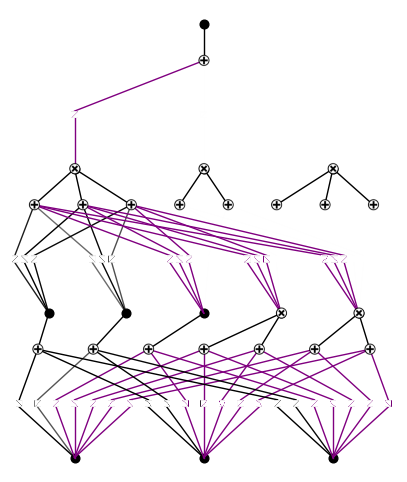

In [8]:
plot(model, train['x'], beta=1000);